# Laboratorium 3 — Czy Fourier potrafi uratować klasyfikację obrazu?
**Metody rozpoznawania obrazów · CIFAR-10 · 15 min wprowadzenia + 75 min laboratorium**

**Hipoteza:** filtr usuwający *wykryte* częstotliwości zakłócenia okresowego poprawi dokładność klasyfikatora wyuczonego na czystych obrazach, bez ponownego uczenia.

- 🏠 **W domu:** uruchom sekcje 0–3, naucz sieć i zapisz pliki wynikowe (`fourier_lab_model.pt`).
- 🎓 **Na zajęciach:** sekcje 4–8: dodaj zakłócenie, *samodzielnie wykryj* dwie częstotliwości, zaprojektuj filtr, przeprowadź porównanie.
- **Zasada eksperymentu:** podział danych i sieć pozostają stałe; filtr dobieramy na zbiorze kalibracyjnym, nie na teście.

Wymagane pakiety: `torch`, `torchvision`, `numpy`, `matplotlib`, `scipy`, `scikit-learn`. Internet jest potrzebny tylko do pierwszego pobrania CIFAR-10.

## 🏠 0. Importy, ziarno losowe i konfiguracja

In [1]:
import random, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import CIFAR10
from sklearn.metrics import accuracy_score, f1_score
from scipy.ndimage import gaussian_filter

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA=Path('./data'); CKPT=Path('fourier_lab_model.pt')
print('Urządzenie:', device)

Urządzenie: cuda


## 🏠 1. Dane: osobne podzbiory i brak przecieku

Używamy 5000 obrazów treningowych i 1000 walidacyjnych z oryginalnej części treningowej CIFAR-10 oraz 1000 obrazów **testowych** z oficjalnej części testowej. Osobny **zbiór kalibracyjny 300 obrazów** pochodzi z oficjalnej części treningowej, ale nie nakłada się na trening ani walidację. Na nim szacujemy widmo zakłóceń. Właściwy test pozostaje nietknięty do końcowej ewaluacji.

In [2]:
train_full=CIFAR10(DATA,train=True,download=True)
test_full=CIFAR10(DATA,train=False,download=True)
rng=np.random.default_rng(SEED)
idx=rng.permutation(len(train_full))
train_idx, val_idx, calib_idx=idx[:5000], idx[5000:6000], idx[6000:6300]
test_idx=rng.permutation(len(test_full))[:1000]

def to_array(ds, ids):
    return np.asarray(ds.data[ids],dtype=np.float32)/255.0, np.asarray(ds.targets,dtype=np.int64)[ids]
Xtr,ytr=to_array(train_full,train_idx)
Xval,yval=to_array(train_full,val_idx)
Xcal,ycal=to_array(train_full,calib_idx)
Xtest,ytest=to_array(test_full,test_idx)
print('train / val / calib / test:',len(Xtr),len(Xval),len(Xcal),len(Xtest))

Files already downloaded and verified
Files already downloaded and verified
train / val / calib / test: 5000 1000 300 1000


## 🏠 2. Mała sieć konwolucyjna (CNN, Convolutional Neural Network)

In [3]:
class ArrayDataset(Dataset):
    def __init__(self,x,y): self.x=x;self.y=y
    def __len__(self): return len(self.y)
    def __getitem__(self,i):
        return torch.from_numpy(self.x[i].transpose(2,0,1).copy()),int(self.y[i])

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((2,2)))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128*2*2,128),nn.ReLU(),nn.Dropout(0.25),nn.Linear(128,10))
    def forward(self,x): return self.classifier(self.features(x))

def evaluate(model,x,y,batch_size=256):
    loader=DataLoader(ArrayDataset(x,y),batch_size=batch_size,shuffle=False)
    model.eval(); preds=[]
    with torch.no_grad():
        for xb,_ in loader:
            preds.extend(model(xb.to(device)).argmax(1).cpu().tolist())
    return dict(accuracy=accuracy_score(y,preds),f1_macro=f1_score(y,preds,average='macro')),np.array(preds)

## 🏠 3. Trening i zapis — wykonaj **przed zajęciami**

Trening ma być wykonany raz. Dla porównania warunków testowych **nie trenuj ponownie**. Gdy plik modelu już istnieje, komórka wczyta go automatycznie.

In [4]:
model=SmallCNN().to(device)
if CKPT.exists():
    model.load_state_dict(torch.load(CKPT,map_location=device,weights_only=True))
    print('Wczytano:',CKPT)
else:
    loader=DataLoader(ArrayDataset(Xtr,ytr),batch_size=128,shuffle=True)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    loss_fn=nn.CrossEntropyLoss()
    best_acc=-1; best_state=None
    for epoch in range(1,9):
        model.train();total=0
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device)
            opt.zero_grad(); loss=loss_fn(model(xb),yb);loss.backward();opt.step()
            total+=float(loss.item())*len(yb)
        val,_=evaluate(model,Xval,yval)
        print(f'Epoka {epoch:2d} | loss {total/len(Xtr):.3f} | val accuracy {val["accuracy"]:.3f}')
        if val['accuracy']>best_acc:
            best_acc=val['accuracy']; best_state=copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    torch.save(model.state_dict(),CKPT)
    print('Zapisano:', CKPT)
print('Wynik walidacyjny:',evaluate(model,Xval,yval)[0])

Wczytano: fourier_lab_model.pt
Wynik walidacyjny: {'accuracy': 0.367, 'f1_macro': 0.3555925821859799}


## 🎓 4. Konstruujemy zakłócenie o *nieznanej studentom częstotliwości* (10 min)

Sinusoida ma pionowe pasy, stałą (ale nieujawnioną w analizie) częstotliwość i niezależną losową fazę dla każdego obrazu. W tym ćwiczeniu kod generatora jest udostępniony, ale podczas szukania częstotliwości **nie odczytuj parametru z kodu**.

Obrazy są reprezentowane przez liczby rzeczywiste: podczas dodawania zakłóceń **nie obcinamy** wartości do [0,1], ponieważ klipowanie generuje dodatkowe harmoniczne. Dopiero do prezentacji używamy `clip`. CNN może przyjąć wartości spoza [0,1].

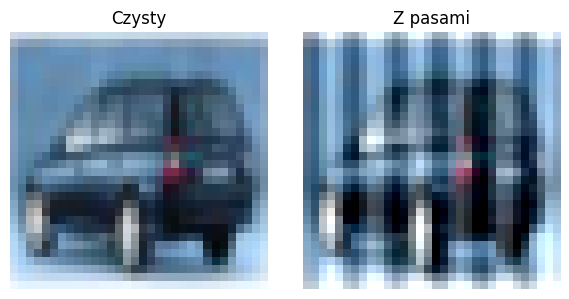

In [5]:
def add_stripes(x, amplitude=0.20, cycles=6, seed=123):
    rng=np.random.default_rng(seed)
    phase=rng.uniform(0,2*np.pi,size=(len(x),1,1,1))
    col=np.arange(x.shape[2],dtype=np.float32)[None,None,:,None]
    noise=amplitude*np.sin(2*np.pi*cycles*col/x.shape[2]+phase)
    return (x+noise.astype(np.float32)).astype(np.float32)

Xcal_noisy=add_stripes(Xcal,seed=31)
Xtest_noisy=add_stripes(Xtest,seed=97)
fig,ax=plt.subplots(1,2,figsize=(6,3))
ax[0].imshow(Xtest[0]);ax[0].set_title('Czysty')
ax[1].imshow(np.clip(Xtest_noisy[0],0,1));ax[1].set_title('Z pasami')
for a in ax:a.axis('off')
plt.tight_layout();plt.show()

## 🎓 5. Analiza amplitudy i fazy (10 min)

Dwuwymiarowa transformata Fouriera (FFT, Fast Fourier Transform):

\(F(u,v)=A(u,v)e^{i
arphi(u,v)}\).

Wykreśl logarytm amplitudy i fazę dla pierwszego kanału. Sprawdź, że odwrotna transformata zespolonego widma dokładnie rekonstruuje dane (z błędem zaokrągleń).

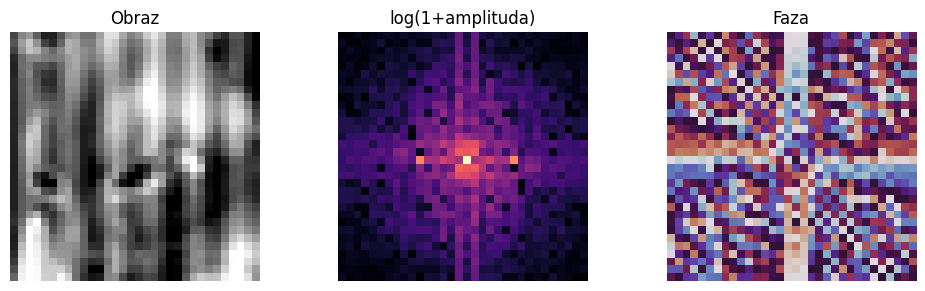

Maksymalny błąd rekonstrukcji: 2.220446049250313e-16


In [6]:
gray=Xcal_noisy[0].mean(axis=2)
F=np.fft.fftshift(np.fft.fft2(gray))
recovered=np.fft.ifft2(np.fft.ifftshift(F)).real
fig,ax=plt.subplots(1,3,figsize=(10,3))
ax[0].imshow(np.clip(gray,0,1),cmap='gray');ax[0].set_title('Obraz')
ax[1].imshow(np.log1p(np.abs(F)),cmap='magma');ax[1].set_title('log(1+amplituda)')
ax[2].imshow(np.angle(F),cmap='twilight',vmin=-np.pi,vmax=np.pi);ax[2].set_title('Faza')
for a in ax:a.axis('off')
plt.tight_layout();plt.show()
print('Maksymalny błąd rekonstrukcji:',np.max(np.abs(gray-recovered)))

## 🎓 6. Wykrycie zakłócających częstotliwości (20 min)

**Zadanie główne.** Dla każdego obrazu kalibracyjnego oblicz FFT2 obrazu uśrednionego po kanałach RGB, następnie **uśrednij moc widma** \(|F|^2\) po wszystkich 300 obrazach. Środek widma odpowiada zerowej częstotliwości.

Wyszukaj silne maksima *poza środkiem widma*. Zakłócenie sinusoidalne rzeczywiste powinno dać **parę symetrycznych maksimów**. Dla obrazu 32×32 środek leży w (wiersz=16, kolumna=16).

**Uwaga metodologiczna:** średnia moc przy losowej fazie zachowuje wąskie piki, podczas gdy średnia zespolonych widm mogłaby je wygasić. Widmo naturalnych obrazów jest silne przy niskich częstotliwościach, dlatego odrzuć dysk wokół środka (promień 3–4 piksele).

**TODO:** wyznacz na podstawie `mean_power` dwie współrzędne `(row, col)`. Nie czytaj `cycles` w generatorze, a do strojenia nie używaj testu.

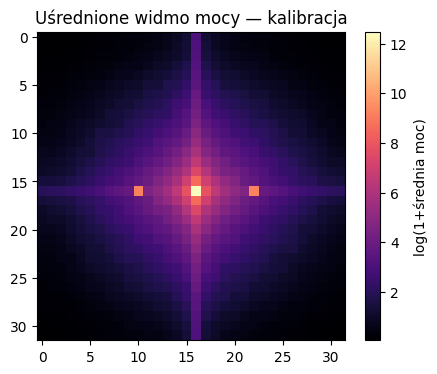

In [7]:
def mean_power_spectrum(x):
    g=x.mean(axis=3)  # (liczba obrazów, 32, 32)
    f=np.fft.fftshift(np.fft.fft2(g,axes=(1,2)),axes=(1,2))
    return (np.abs(f)**2).mean(axis=0)

power_cal=mean_power_spectrum(Xcal_noisy)
plt.figure(figsize=(5,4))
plt.imshow(np.log1p(power_cal),cmap='magma');plt.colorbar(label='log(1+średnia moc)')
plt.title('Uśrednione widmo mocy — kalibracja');plt.show()

**Uzupełnij następną funkcję.** Prostą wersję możesz zbudować z `np.argmax` po wyłączeniu centralnego dysku; następnie zweryfikuj symetrię drugiego maksimum. Uwaga: większa niezawodność możliwa dzięki uwzględnieniu symetrii przy ocenie kandydatów.

In [ ]:
def detect_pair(power, exclude_radius=4):
    h, w = power.shape
    cy, cx = h // 2, w // 2

    yy, xx = np.indices((h, w))

    allowed = (yy-cy)**2 + (xx-cx)**2 > exclude_radius**2

    opposite_y = (2*cy - yy) % h
    opposite_x = (2*cx - xx) % w

    allowed &= (yy != opposite_y) | (xx != opposite_x)

    score = power + power[opposite_y, opposite_x]
    score[~allowed] = -np.inf

    peak1 = np.unravel_index(np.argmax(score), score.shape)
    peak2 = (
        int(opposite_y[peak1]),
        int(opposite_x[peak1])
    )

    return peak1, peak2

peak1,peak2=detect_pair(power_cal)
print('Wykryta para:',peak1,peak2)

Wykryta para: (16, 10) (16, 22)


## 🎓 7. Filtr zaporowy i eksperyment kontrolny (20 min)

W przypadku pionowych pasów energia znajduje się w wąskiej parze punktów widma. Zbuduj **notch filter** (filtr zaporowy) tłumiący *oba* wykryte maksima we wszystkich trzech kanałach. Zachowaj pozostałe zespolone współczynniki (amplitudę i fazę). Wykonaj odwrotną FFT.

Dla uczciwego porównania zastosuj ten sam filtr do zbioru testowego. Przygotuj też prosty filtr Gaussa w dziedzinie obrazu. **Przestrzenna filtracja Gaussowska i notch nie mają tego samego celu**, więc ich wyniki są punktem odniesienia, a nie dowodem uniwersalnej wyższości jednej metody.

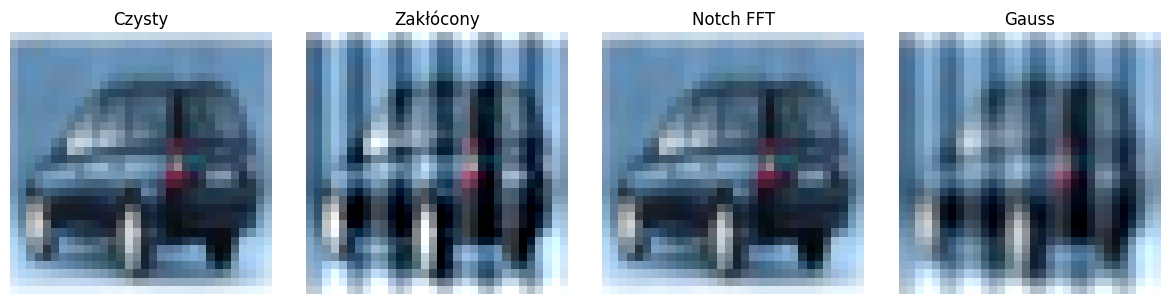

In [9]:
def notch_reconstruct(x, peaks, radius=0):
    # FFT po osiach przestrzennych: x ma wymiar (N, H, W, C)
    spec=np.fft.fftshift(np.fft.fft2(x,axes=(1,2)),axes=(1,2))
    mask=np.ones(x.shape[1:3],dtype=np.float32)
    yy,xx=np.ogrid[:x.shape[1],:x.shape[2]]
    for row,col in peaks:
        mask[(yy-row)**2+(xx-col)**2<=radius**2]=0
    filt=spec*mask[None,:,:,None]
    return np.fft.ifft2(np.fft.ifftshift(filt,axes=(1,2)),axes=(1,2)).real.astype(np.float32)

def gaussian_reconstruct(x,sigma=0.7):
    return gaussian_filter(x,sigma=(0,sigma,sigma,0)).astype(np.float32)

Xtest_notch=notch_reconstruct(Xtest_noisy,[peak1,peak2])
Xtest_gauss=gaussian_reconstruct(Xtest_noisy)
fig,ax=plt.subplots(1,4,figsize=(12,3))
for a,img,title in zip(ax,[Xtest[0],Xtest_noisy[0],Xtest_notch[0],Xtest_gauss[0]],
                       ['Czysty','Zakłócony','Notch FFT','Gauss']):
    a.imshow(np.clip(img,0,1));a.set_title(title);a.axis('off')
plt.tight_layout();plt.show()

## 🎓 8. Dokładność, F1 i wnioski (15 min)

Oblicz dokładność i F1-macro na **tym samym** zbiorze testowym. Policz także błąd średniokwadratowy (MSE, Mean Squared Error) względem obrazów czystych. Filtr usuwający częstotliwość szumu usuwa również autentyczną informację z obrazu — wynik nie musi wrócić do poziomu zbioru czystego.

In [10]:
conditions={'Czyste':Xtest,'Zakłócone':Xtest_noisy,'FFT notch':Xtest_notch,'Gauss':Xtest_gauss}
results={}
for name,x in conditions.items():
    metric,_=evaluate(model,x,ytest)
    metric['mse']=float(np.mean((x-Xtest)**2))
    results[name]=metric
print(f'{"Warunek":12s} {"Accuracy":>10s} {"F1 macro":>10s} {"MSE":>12s}')
for name,m in results.items():
    print(f'{name:12s} {m["accuracy"]:10.3f} {m["f1_macro"]:10.3f} {m["mse"]:12.5f}')
print('Zysk notch względem zakłóceń [punkty procentowe]:',
      round(100*(results['FFT notch']['accuracy']-results['Zakłócone']['accuracy']),2))

Warunek        Accuracy   F1 macro          MSE
Czyste            0.418      0.405      0.00000
Zakłócone         0.343      0.304      0.02000
FFT notch         0.418      0.406      0.00013
Gauss             0.371      0.371      0.01194
Zysk notch względem zakłóceń [punkty procentowe]: 7.5


### Do oddania — krótka odpowiedź (maks. 1 strona)

1. Jakie dwie współrzędne znaleziono w uśrednionym widmie? Skąd wiadomo, że tworzą parę?
2. Podaj cztery wiersze wyników: czyste / zakłócone / notch / Gauss (accuracy, F1-macro i MSE). Jaki jest zysk w punktach procentowych?
3. Dlaczego nie wolno odtworzyć obrazu z samej amplitudy? Co stałoby się po uśrednieniu zespolonych widm przy losowej fazie zakłócenia?
4. Dlaczego notch może być lepszy od wygładzania Gaussowskiego *w tym konkretnym eksperymencie*? Czy może również zaszkodzić?
5. Podaj 1–3 pytania skierowane do modelu językowego, jeżeli korzystałeś/-aś z jego pomocy, oraz sposób weryfikacji odpowiedzi.

**Rozszerzenie (opcjonalne):** sprawdź amplitudy 0.10, 0.20, 0.30 lub wybierz inny promień wycięcia piku. Wybór parametrów przeprowadź na kalibracji/walidacji, nie na zbiorze testowym.

**Literatura:** Yin et al., *A Fourier Perspective on Model Robustness in Computer Vision*, NeurIPS 2019; Chen et al., *Amplitude-Phase Recombination*, ICCV 2021.